In [2]:
import warnings
warnings.filterwarnings('ignore')

import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns

from enigmatoolbox.plotting import plot_cortical, plot_subcortical
from enigmatoolbox.utils.parcellation import parcel_to_surface

import sys
sys.path.append('..')

from helper.func import general_linear_model

In [ ]:
project_dir = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
results_dir = os.path.join(project_dir, '...', '...')

In [ ]:
## Demographics
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'), index_col=0)
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

## cortical thickness
ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle.csv'), index_col=0)
ctx_ige = pd.read_csv(os.path.join(results_dir, '...', 'ctx_ige.csv'), index_col=0)

## subcortical volume
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle.csv'), index_col=0)
sv_ige = pd.read_csv(os.path.join(results_dir, '...', 'sv_ige.csv'), index_col=0)

In [6]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib as mpl

my_rdbu = LinearSegmentedColormap.from_list(
    "my_rdbu", ["#174fa0", "#2f89c2", "#f7f7f7", "#df5948", "#ad0c28"], N=256)

try:
    mpl.colormaps.register(my_rdbu)
except ValueError:
    pass

## Effects of diagnosis in males

In [6]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

male_diagnosis = {}

for epi in ['tle', 'ige']:
    male_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv']:
        male_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"
        male_diagnosis[epi][biomarker] = glm.diagnosis_effects_across_sexes(
            df_name=df_name, group_col='Dx', age_col='Age',
            sex_col='Sex', icv_col='ICV', gender='male'
        )

2026-08-29 10:58:57,054 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.


2026-08-29 10:58:57,129 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-08-29 10:58:57,142 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-08-29 10:58:57,172 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.


In [7]:
## reorganize the result
metrics = ['t', 'q', 'cohen']
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

male_metrics = {}
for metric in metrics: 
    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'
        male_metrics[key] = None

for metric in metrics:
    metric_key = f"{metric}_values" if metric != 'cohen' else 'cohen_d'
    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'
        stacked_values = []
        
        for epi in epi_types:
            stacked_values.append(male_diagnosis[epi][biomarker][metric_key])
        
        male_metrics[key] = np.vstack(stacked_values)

In [ ]:
## Save 
metrics_to_save = ['t', 'q', 'cohen']
epi_to_save = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...', 'males')
os.makedirs(output_base, exist_ok=True)

for epi_idx, epi in enumerate(epi_to_save):

    epi_dir = os.path.join(output_base, epi.upper())
    os.makedirs(epi_dir, exist_ok=True)

    for biomarker in biomarkers:
        index_cols = biomarker_index_map[biomarker]
        for metric in metrics_to_save:
            key = f'{metric}_{biomarker}'

            if key not in male_metrics:
                continue

            values = male_metrics[key][epi_idx, :]

            assert len(values) == len(index_cols), \
                f"{key}: region dimension mismatch"

            df = pd.DataFrame({metric: values}, index=index_cols)
            df['epi'] = epi
            df['biomarker'] = biomarker
            df['metric'] = metric

            out_name = f'{metric}_{biomarker}.csv'
            df.to_csv(os.path.join(epi_dir, out_name), index=True)

Cortical thickness in TLE

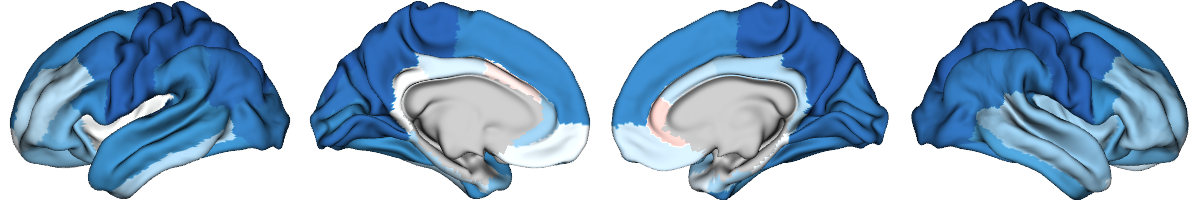

In [32]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(male_metrics['cohen_ctx'][0], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.4, 0.4))

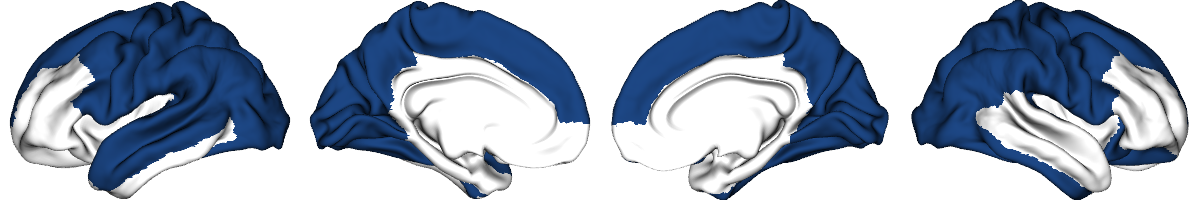

In [63]:
# plot p significant regions in TLE

p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [36]:
## Check which areas are significant
q_ctx_tle = pd.Series(male_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')

# brain areas where tle showed significance
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_bankssts', 'L_caudalmiddlefrontal', 'L_cuneus', 'L_fusiform',
       'L_inferiorparietal', 'L_lateraloccipital', 'L_lingual',
       'L_middletemporal', 'L_paracentral', 'L_parsopercularis',
       'L_pericalcarine', 'L_postcentral', 'L_precentral', 'L_precuneus',
       'L_superiorfrontal', 'L_superiorparietal', 'L_superiortemporal',
       'L_supramarginal', 'L_transversetemporal', 'R_caudalmiddlefrontal',
       'R_cuneus', 'R_fusiform', 'R_inferiorparietal', 'R_inferiortemporal',
       'R_lateraloccipital', 'R_lateralorbitofrontal', 'R_lingual',
       'R_paracentral', 'R_parsopercularis', 'R_pericalcarine',
       'R_postcentral', 'R_precentral', 'R_precuneus', 'R_superiorfrontal',
       'R_superiorparietal', 'R_supramarginal', 'R_transversetemporal'],
      dtype='object')

In [37]:
len(q_ctx_tle[q_ctx_tle < 0.05])

37

In [38]:
# get the cohen's d values range for TLE in males
male_metrics['cohen_ctx'][0].min(), male_metrics['cohen_ctx'][0].max()

(-0.4941325164115689, 0.063775587186924)

In [39]:
# get the strongest effects (cohen's d values) for p significant regions for TLE in males
cohen_ctx_tle = pd.Series(male_metrics['cohen_ctx'][0], index=ctx_tle.columns, name="Cohen's_d")

tle_ctx = pd.DataFrame({
    "Cohen's d": cohen_ctx_tle,
    "q-value": q_ctx_tle
})

# 3️⃣ Filter by significance and sort by Cohen's d (ascending = lowest first)
tle_sig_ctx = tle_ctx[tle_ctx["q-value"] < 0.05].sort_values(by="Cohen's d", ascending=True)
tle_sig_ctx.head(15)

,Cohen's d,q-value
R_paracentral,-0.494133,1.509299e-09
R_postcentral,-0.460254,1.067547e-08
R_superiorparietal,-0.459102,1.067547e-08
L_postcentral,-0.430143,7.829715e-08
R_precentral,-0.428588,7.829715e-08
L_superiorparietal,-0.424861,8.767967e-08
L_precentral,-0.420830,9.949169e-08
R_precuneus,-0.419592,9.949169e-08
L_paracentral,-0.393575,6.395914e-07
L_precuneus,-0.376187,2.031085e-06


IGE

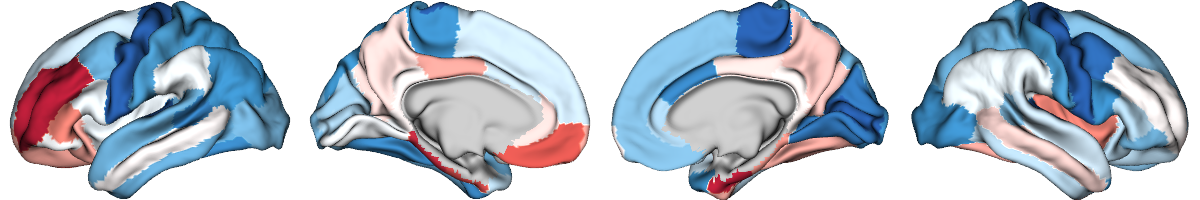

In [40]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(male_metrics['cohen_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.4, 0.4))

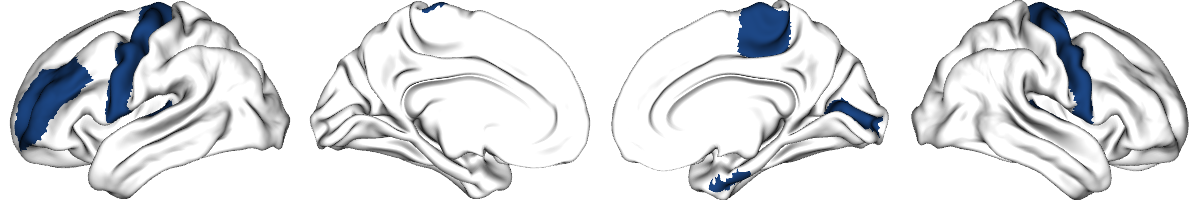

In [62]:
# plot p significant regions in IGE
p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [44]:
## Check which areas are significant
q_ctx_ige = pd.Series(male_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05]

L_precentral              0.008959
L_rostralmiddlefrontal    0.015022
L_transversetemporal      0.025482
R_entorhinal              0.008959
R_paracentral             0.000570
R_pericalcarine           0.015022
R_precentral              0.008959
R_transversetemporal      0.008959
Name: pFDR, dtype: float64

In [24]:
# get the cohen's d values range for IGE in males
male_metrics['cohen_ctx'][1].min(), male_metrics['cohen_ctx'][1].max()

(-0.6343083894685294, 0.5137529694037428)

In [25]:
# get the cohen's d values for p significant regions for IGE in males
cohen_ctx_ige = pd.Series(male_metrics['cohen_ctx'][1], index=ctx_ige.columns, name='pFDR')

ige_ctx = pd.DataFrame({
    "Cohen's d": cohen_ctx_ige,
    "q-value": q_ctx_ige
})

ige_sig_ctx = ige_ctx[ige_ctx["q-value"] < 0.05].sort_values(by="Cohen's d", ascending=True)
ige_sig_ctx

,Cohen's d,q-value
R_paracentral,-0.634308,0.000570
R_precentral,-0.484078,0.008959
R_transversetemporal,-0.484061,0.008959
L_precentral,-0.480528,0.008959
R_pericalcarine,-0.449412,0.015022
L_transversetemporal,-0.417410,0.025482
L_rostralmiddlefrontal,0.445838,0.015022
R_entorhinal,0.513753,0.008959


Subcortical volumes in TLE

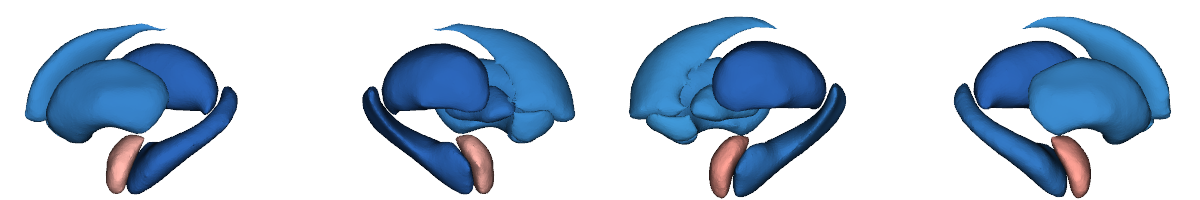

In [47]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['cohen_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.4, 0.4))


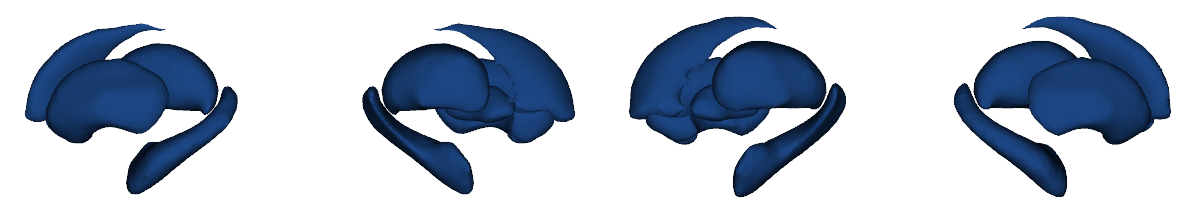

In [61]:
# plot p significant regions in TLE
sig_mask = np.where(male_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [49]:
## Check which subcortical areas are significant in TLE
q_sv_tle = pd.Series(male_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')

q_sv_tle[q_sv_tle < 0.05].index

Index(['Laccumb', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal', 'Raccumb',
       'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [50]:
# get the cohen's d values range for TLE in males
male_metrics['cohen_sv'][0].min(), male_metrics['cohen_sv'][0].max()

(-0.516933812840757, 0.1362969397086048)

In [51]:
# get the strongest effects (cohen's d values) for p significant subcortical regions for TLE in males
cohen_sv_tle = pd.Series(male_metrics['cohen_sv'][0], index=sv_tle.columns, name="Cohen's_d")

tle_sv = pd.DataFrame({
    "Cohen's d": cohen_sv_tle,
    "q-value": q_sv_tle
})

# 3️⃣ Filter by significance and sort by Cohen's d (ascending = lowest first)
tle_sig_sv = tle_sv[tle_sv["q-value"] < 0.05].sort_values(by="Cohen's d", ascending=True)
tle_sig_sv.head(10)

,Cohen's d,q-value
Rthal,-0.516934,3.844868e-11
Lthal,-0.480486,5.229255e-10
Lhippo,-0.423060,4.163305e-08
Lpal,-0.350969,5.958204e-06
Rhippo,-0.336928,1.199921e-05
Lput,-0.301635,8.801858e-05
Lcaud,-0.280706,2.482292e-04
Laccumb,-0.276749,2.698058e-04
Rput,-0.272489,3.020080e-04
Rpal,-0.256696,6.219947e-04


IGE

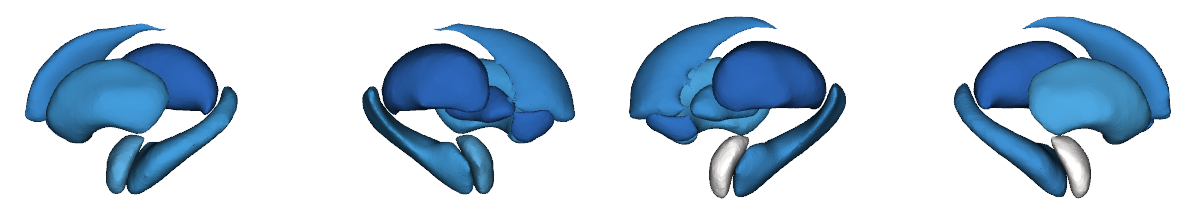

In [52]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['cohen_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.4, 0.4))

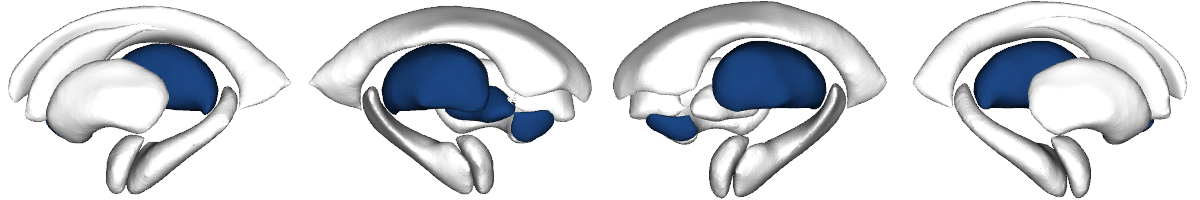

In [60]:
# plot p significant regions in IGE
sig_mask = np.where(male_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), ventricles=False, zoom=1.8, nan_color=(1, 1, 1, 1), interactive=False, embed_nb=True, 
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [65]:
## Check which subcortical areas are significant in IGE
q_sv_ige = pd.Series(male_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05]

Laccumb    0.003459
Lpal       0.007809
Lthal      0.003459
Raccumb    0.024329
Rthal      0.001752
Name: pFDR, dtype: float64

In [66]:
# get the cohen's d values range for IGE in males
male_metrics['cohen_sv'][1].min(), male_metrics['cohen_sv'][1].max()

(-0.5430526541788909, 0.005341844956144874)

In [67]:
# get the cohen's d values for p significant subcortical regions for IGE in males
cohen_sv_ige = pd.Series(male_metrics['cohen_sv'][1], index=sv_ige.columns, name="Cohen's_d")

ige_sv = pd.DataFrame({
    "Cohen's d": cohen_sv_ige,
    "q-value": q_sv_ige
})

ige_sig_sv = ige_sv[ige_sv["q-value"] < 0.05].sort_values(by="Cohen's d", ascending=True)
ige_sig_sv

,Cohen's d,q-value
Rthal,-0.543053,0.001752
Laccumb,-0.486589,0.003459
Lthal,-0.475874,0.003459
Lpal,-0.430297,0.007809
Raccumb,-0.368276,0.024329


## Effects of diagnosis in females

In [68]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

female_diagnosis = {}

for epi in ['tle', 'ige']:
    female_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv', 'sa']:
        female_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        female_diagnosis[epi][biomarker] = glm.diagnosis_effects_across_sexes(
            df_name=df_name, group_col='Dx', age_col='Age',
            sex_col='Sex', icv_col='ICV', gender='female'
        )

2026-08-29 11:27:37,040 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-08-29 11:27:37,057 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-08-29 11:27:37,071 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-08-29 11:27:37,094 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical v

In [69]:
## reorganize the result
metrics = ['t', 'q', 'cohen']
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

female_metrics = {}

for metric in metrics:
    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'
        female_metrics[key] = None

for metric in metrics:
    metric_key = f"{metric}_values" if metric != 'cohen' else 'cohen_d'

    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'
        stacked_values = []
        for epi in epi_types:
            stacked_values.append(female_diagnosis[epi][biomarker][metric_key])
            
        female_metrics[key] = np.vstack(stacked_values)

In [ ]:
## Save 
metrics_to_save = ['t', 'q', 'cohen']
epi_to_save = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...', 'females')
os.makedirs(output_base, exist_ok=True)

for epi_idx, epi in enumerate(epi_to_save):

    epi_dir = os.path.join(output_base, epi.upper())
    os.makedirs(epi_dir, exist_ok=True)

    for biomarker in biomarkers:
        index_cols = biomarker_index_map[biomarker]
        for metric in metrics_to_save:
            key = f'{metric}_{biomarker}'

            if key not in female_metrics:
                continue

            values = female_metrics[key][epi_idx, :]

            assert len(values) == len(index_cols), \
                f"{key}: region dimension mismatch"

            df = pd.DataFrame({metric: values}, index=index_cols)
            df['epi'] = epi
            df['biomarker'] = biomarker
            df['metric'] = metric

            out_name = f'{metric}_{biomarker}.csv'
            df.to_csv(os.path.join(epi_dir, out_name), index=True)

Cortical thickness in TLE

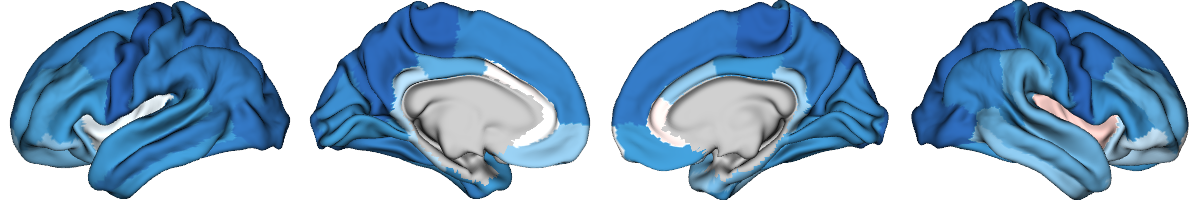

In [71]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(female_metrics['cohen_ctx'][0], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.4, 0.4))

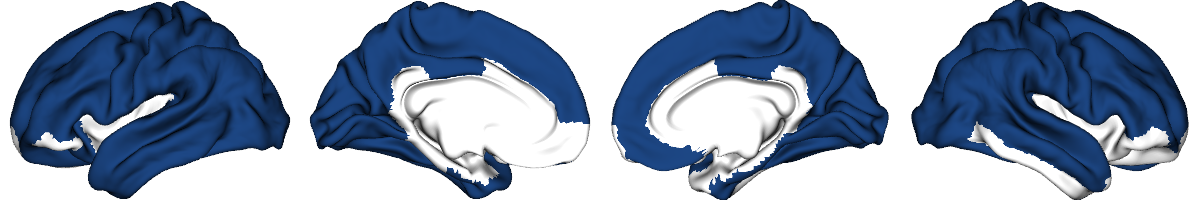

In [74]:
# plot p-sig areas in TLE
p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [75]:
## Check which areas are significant
q_ctx_tle = pd.Series(female_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_bankssts', 'L_caudalmiddlefrontal', 'L_cuneus', 'L_entorhinal',
       'L_fusiform', 'L_inferiorparietal', 'L_inferiortemporal',
       'L_lateraloccipital', 'L_lateralorbitofrontal', 'L_lingual',
       'L_middletemporal', 'L_paracentral', 'L_parsopercularis',
       'L_parstriangularis', 'L_pericalcarine', 'L_postcentral',
       'L_posteriorcingulate', 'L_precentral', 'L_precuneus',
       'L_rostralmiddlefrontal', 'L_superiorfrontal', 'L_superiorparietal',
       'L_superiortemporal', 'L_supramarginal', 'L_temporalpole',
       'L_transversetemporal', 'R_bankssts', 'R_caudalmiddlefrontal',
       'R_cuneus', 'R_entorhinal', 'R_fusiform', 'R_inferiorparietal',
       'R_lateraloccipital', 'R_lingual', 'R_medialorbitofrontal',
       'R_middletemporal', 'R_parahippocampal', 'R_paracentral',
       'R_parsopercularis', 'R_parstriangularis', 'R_pericalcarine',
       'R_postcentral', 'R_posteriorcingulate', 'R_precentral', 'R_precuneus',
       'R_rostralmiddlefrontal', 'R_su

In [76]:
len(q_ctx_tle[q_ctx_tle < 0.05])

51

In [77]:
# get the cohen's d values range for TLE in females
female_metrics['cohen_ctx'][0].min(), female_metrics['cohen_ctx'][0].max()

(-0.4545256030182089, 0.06651161244814524)

In [78]:
cohen_ctx_tle = pd.Series(female_metrics['cohen_ctx'][0], index=ctx_tle.columns, name="Cohen's_d")

tle_ctx = pd.DataFrame({
    "Cohen's d": cohen_ctx_tle,
    "q-value": q_ctx_tle
})

tle_sig_ctx = tle_ctx[tle_ctx["q-value"] < 0.05].sort_values(by="Cohen's d", ascending=True)
tle_sig_ctx.head(10)

,Cohen's d,q-value
R_paracentral,-0.454526,5.490487e-10
L_precentral,-0.448689,5.490487e-10
L_paracentral,-0.407948,1.895094e-08
R_precentral,-0.398348,3.433899e-08
R_superiorparietal,-0.380944,1.296954e-07
L_precuneus,-0.378436,1.344838e-07
R_lateraloccipital,-0.373772,1.725143e-07
R_caudalmiddlefrontal,-0.353866,8.028034e-07
L_superiorparietal,-0.348745,1.082639e-06
L_lateraloccipital,-0.338341,2.235402e-06


IGE

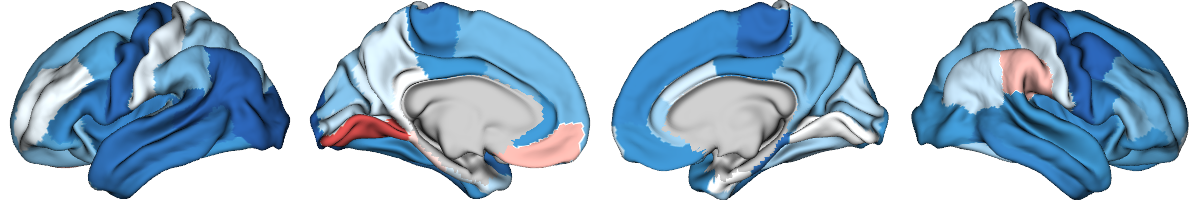

In [79]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(female_metrics['cohen_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.4, 0.4))

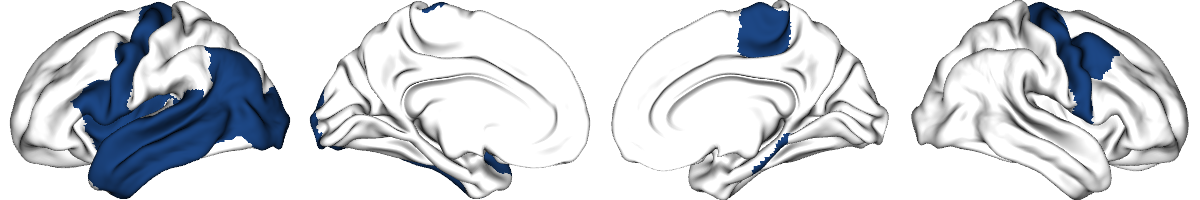

In [82]:
# plot p-sig areas in IGE

p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [83]:
## Check which areas are significant
q_ctx_ige = pd.Series(female_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')

q_ctx_ige[q_ctx_ige < 0.05].index

Index(['L_bankssts', 'L_inferiorparietal', 'L_inferiortemporal',
       'L_lateraloccipital', 'L_middletemporal', 'L_parsopercularis',
       'L_precentral', 'L_superiortemporal', 'L_insula',
       'R_caudalmiddlefrontal', 'R_parahippocampal', 'R_paracentral',
       'R_precentral'],
      dtype='object')

In [84]:
len(q_ctx_ige[q_ctx_ige < 0.05])

13

In [85]:
female_metrics['cohen_ctx'][1].min(), female_metrics['cohen_ctx'][1].max()

(-0.44486618469447775, 0.2663804842141162)

In [86]:
cohen_ctx_ige = pd.Series(female_metrics['cohen_ctx'][1], index=ctx_ige.columns, name='pFDR')

ige_ctx = pd.DataFrame({
    "Cohen's d": cohen_ctx_ige,
    "q-value": q_ctx_ige
})

ige_sig_ctx = ige_ctx[ige_ctx["q-value"] < 0.05].sort_values(by="Cohen's d", ascending=True)
ige_sig_ctx

,Cohen's d,q-value
L_inferiorparietal,-0.444866,0.002342
R_caudalmiddlefrontal,-0.438779,0.002342
L_bankssts,-0.412449,0.004070
L_lateraloccipital,-0.394857,0.005480
R_precentral,-0.389126,0.005480
L_precentral,-0.373196,0.007759
R_paracentral,-0.362148,0.009503
R_parahippocampal,-0.349478,0.012388
L_superiortemporal,-0.338501,0.015409
L_middletemporal,-0.321884,0.022690


Subcortical volumes in TLE

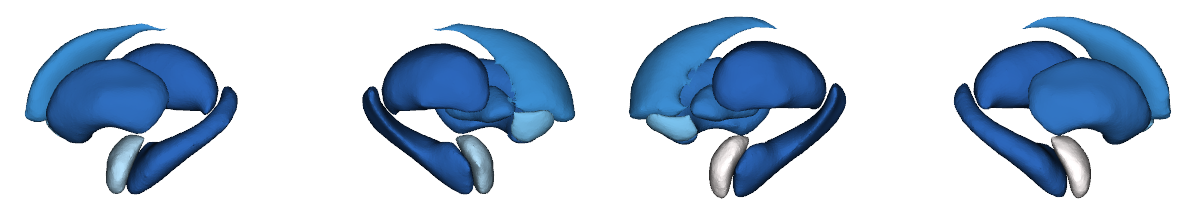

In [88]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['cohen_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.4, 0.4))


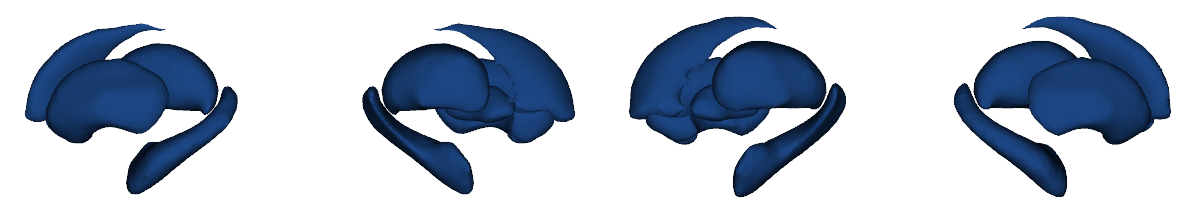

In [89]:
# plot p-sig areas in TLE

sig_mask = np.where(female_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [90]:
## Check which subcortical areas are significant in TLE
q_sv_tle = pd.Series(female_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index(['Laccumb', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal', 'Raccumb',
       'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [91]:
female_metrics['cohen_sv'][0].min(), female_metrics['cohen_sv'][0].max()

(-0.5767713384415049, 0.006501989132537236)

In [92]:
cohen_sv_tle = pd.Series(female_metrics['cohen_sv'][0], index=sv_tle.columns, name="Cohen's_d")

tle_sv = pd.DataFrame({
    "Cohen's d": cohen_sv_tle,
    "q-value": q_sv_tle
})

tle_sig_sv = tle_sv[tle_sv["q-value"] < 0.05].sort_values(by="Cohen's d", ascending=True)
tle_sig_sv.head(10)

,Cohen's d,q-value
Rthal,-0.576771,7.789082e-17
Lhippo,-0.574429,7.789082e-17
Lthal,-0.552069,8.026245e-16
Rhippo,-0.525544,1.376224e-14
Lput,-0.372485,5.554747e-08
Rput,-0.349348,3.184750e-07
Lpal,-0.327578,1.516573e-06
Rpal,-0.322059,2.017996e-06
Rcaud,-0.273814,5.355225e-05
Lcaud,-0.266881,7.545949e-05


IGE

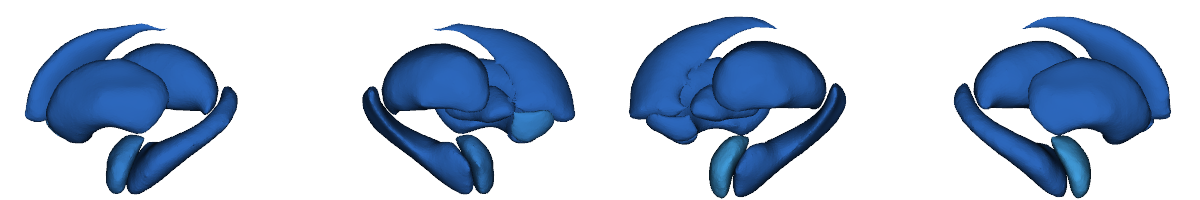

In [93]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['cohen_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.4, 0.4))

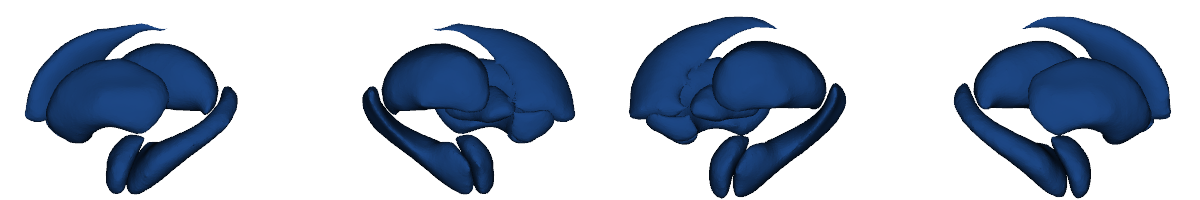

In [94]:
# plot p-sig areas in IGE
sig_mask = np.where(female_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [95]:
## Check which subcortical areas are significant in IGE
q_sv_ige = pd.Series(female_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [96]:
female_metrics['cohen_sv'][1].min(), female_metrics['cohen_sv'][1].max()

(-0.5235441197594186, -0.22687839281829347)

In [97]:
cohen_sv_ige = pd.Series(female_metrics['cohen_sv'][1], index=sv_ige.columns, name="Cohen's_d")

ige_sv = pd.DataFrame({
    "Cohen's d": cohen_sv_ige,
    "q-value": q_sv_ige
})

ige_sig_sv = ige_sv[ige_sv["q-value"] < 0.05].sort_values(by="Cohen's d", ascending=True)
ige_sig_sv

,Cohen's d,q-value
Lpal,-0.523544,0.000018
Rthal,-0.521176,0.000018
Rcaud,-0.507703,0.000021
Rpal,-0.483316,0.000036
Lthal,-0.482133,0.000036
Rhippo,-0.476791,0.000037
Lcaud,-0.469998,0.000042
Lhippo,-0.428564,0.000176
Raccumb,-0.423557,0.000188
Lput,-0.408500,0.000282


## Effect of sex and diagnosis-sex interaction across cohorts

In [7]:
## glm comparison 
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

comparison_types = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

results = {}
for epi in ['tle', 'ige']:
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.biomarker_comparison(
                df_name=df_name, comparison_type=comparison_type, age_col='Age',
                sex_col='Sex', icv_col='ICV', group_col='Dx'
            )

2026-08-31 11:52:16,220 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.


2026-08-31 11:52:16,225 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-08-31 11:52:16,275 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-08-31 11:52:16,305 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-08-31 11:52:16,318 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variabl

In [8]:
# reorganize the results

comparison_types = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

metric_map = {
    't': 't_values', 'p': 'p_values', 'q': 'q_values',
    'beta': 'beta', 'ci_lower': 'ci_lower', 'ci_upper': 'ci_upper', 'cohen': 'cohen_d'
}

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:
        for metric_name, result_key in metric_map.items():

            values = np.vstack([
                results[epi][biomarker][comparison_type][result_key]
                for comparison_type in comparison_types
            ])

            result_dicts[f'{metric_name}_{epi}_{biomarker}'] = values

In [ ]:
comparison_types = ['sex_in_epi', 'sex_in_hc', 'sex_group_interaction']
metrics_to_save = ['t', 'p', 'q', 'beta', 'ci_lower', 'ci_upper', 'cohen']
biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...', 'sex_effects')
os.makedirs(output_base, exist_ok=True)

for epi in ['tle', 'ige']:
    epi_dir = os.path.join(output_base, epi.upper())
    os.makedirs(epi_dir, exist_ok=True)

    for biomarker in ['ctx', 'sv']:
        index_cols = biomarker_index_map[biomarker]

        for metric in metrics_to_save:
            key = f'{metric}_{epi}_{biomarker}'
            if key not in result_dicts: continue

            values = result_dicts[key][1:, :]

            assert values.shape[0] == len(comparison_types), f'{key}: comparison dim mismatch'
            assert values.shape[1] == len(index_cols), f'{key}: region dim mismatch'

            df = pd.DataFrame(values.T, index=index_cols, columns=comparison_types)
            df[['epi', 'biomarker', 'metric']] = [epi, biomarker, metric]
            
            df.to_csv(os.path.join(epi_dir, f'{metric}_{biomarker}.csv'), index=True)

### TLE results visualization

#### Cortical thickness 

##### Sex effects in TLE

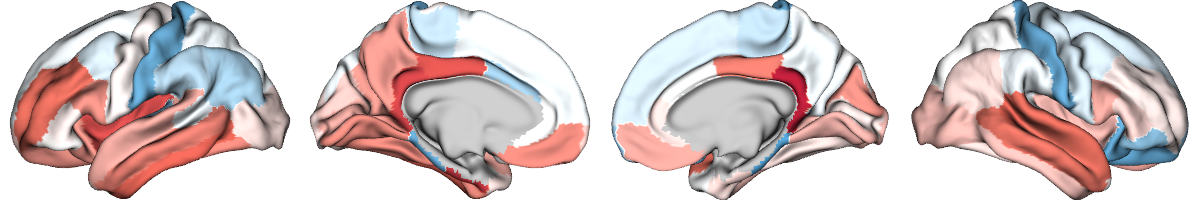

In [11]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

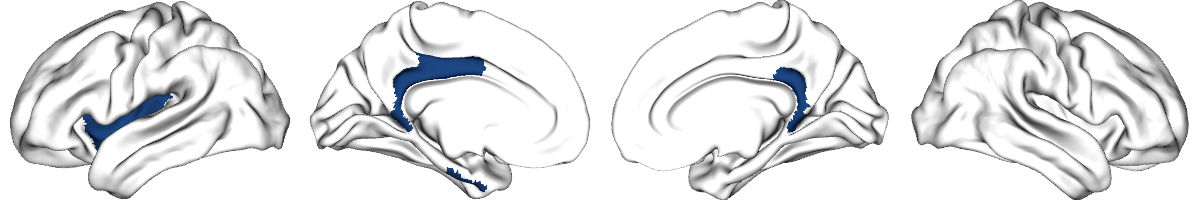

In [14]:
# plot p-sig areas in TLE

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [15]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][1], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_entorhinal', 'L_isthmuscingulate', 'L_posteriorcingulate',
       'L_insula', 'R_isthmuscingulate'],
      dtype='object')

In [16]:
len(q_ctx_tle[q_ctx_tle < 0.05])

5

In [17]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_ctx'][1].min(), result_dicts['cohen_tle_ctx'][1].max()

(-0.13566689474883545, 0.29838077685248915)

In [18]:
# get the strongest effects (cohen's d values) for p significant regions for TLE in males
cohen_ctx_tle = pd.Series(result_dicts['cohen_tle_ctx'][1], index=ctx_tle.columns, name="Cohen's_d")

tle_ctx = pd.DataFrame({
    "Cohen's d": cohen_ctx_tle,
    "q-value": q_ctx_tle
})

tle_sig_ctx = tle_ctx[tle_ctx["q-value"] < 0.05].sort_values(by="Cohen's d", ascending=True)
tle_sig_ctx

,Cohen's d,q-value
L_posteriorcingulate,0.188472,0.035126
L_insula,0.200192,0.023366
L_isthmuscingulate,0.219669,0.010175
L_entorhinal,0.239460,0.004472
R_isthmuscingulate,0.298381,0.000135


Sex effects in healthy control

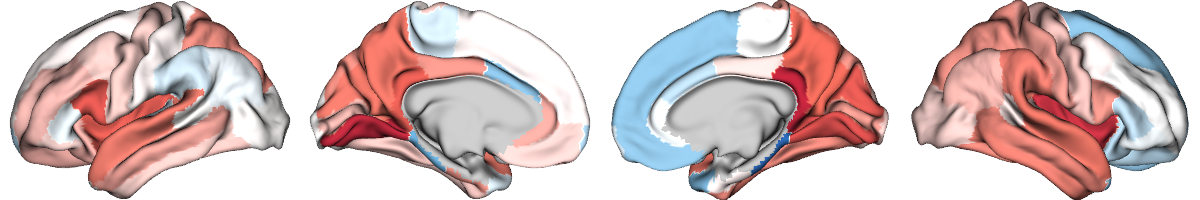

In [20]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][2], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

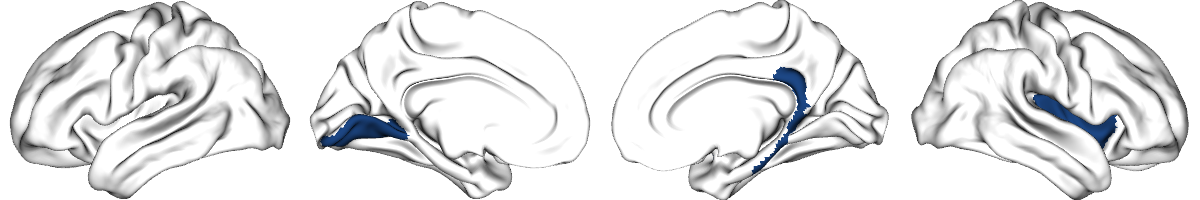

In [25]:
# plot p-sig areas in TLE

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][2], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [26]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']
q_ctx_hc = pd.Series(result_dicts['q_tle_ctx'][2], index=ctx_tle.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index(['L_lingual', 'R_isthmuscingulate', 'R_parahippocampal', 'R_insula'], dtype='object')

In [27]:
len(q_ctx_hc[q_ctx_hc < 0.05])

4

In [28]:
# get the cohen's d values range for sex in healthy control
result_dicts['cohen_tle_ctx'][2].min(), result_dicts['cohen_tle_ctx'][2].max()

(-0.27991052806188377, 0.28796101759858017)

Sex effects in interaction

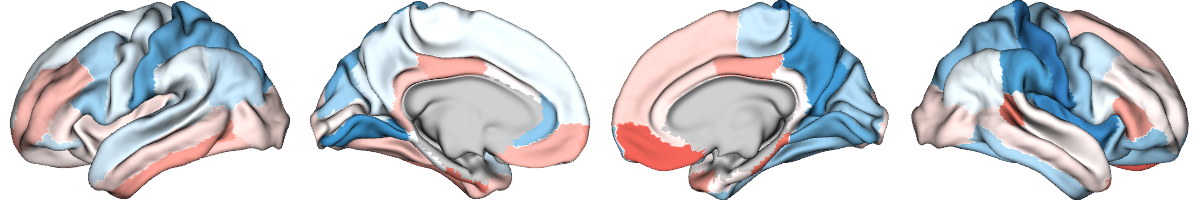

In [33]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['t_tle_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

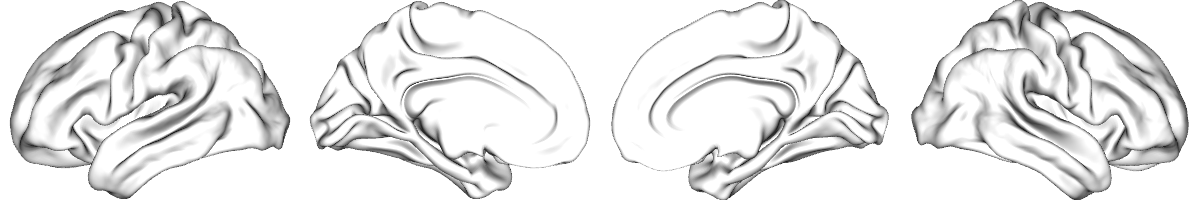

In [34]:
# plot p-sig areas in TLE
p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [35]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

q_ctx_hc = pd.Series(result_dicts['q_tle_ctx'][3], index=ctx_tle.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index([], dtype='object')

In [36]:
len(q_ctx_hc[q_ctx_hc < 0.05])

0

In [37]:
# get the cohen's d values range for sex in healthy control
result_dicts['t_tle_ctx'][3].min(), result_dicts['t_tle_ctx'][3].max()

(-2.1533351508057743, 1.7051746265197496)

Subcortical volume

Sex effects in epi

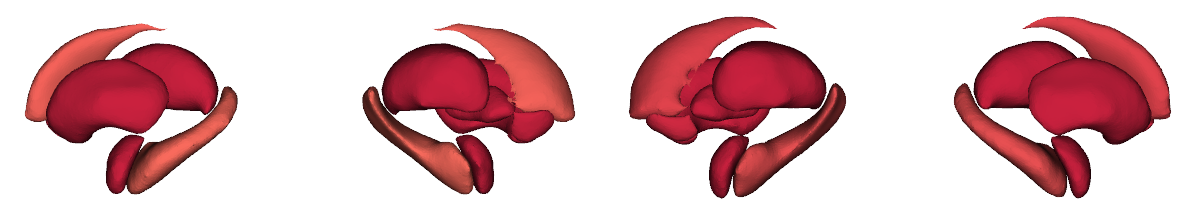

In [38]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_tle_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))


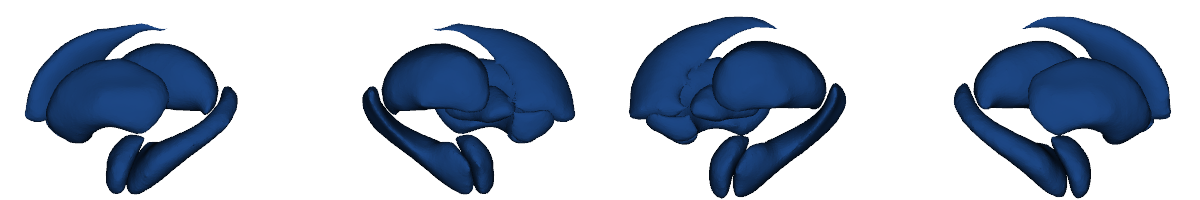

In [39]:
# plot p-sig areas in TLE

sig_mask = np.where(result_dicts['q_tle_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [40]:
## Check which areas are significant in epilepsy
q_sv_tle = pd.Series(result_dicts['q_tle_sv'][1], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [41]:
len(q_sv_tle[q_sv_tle < 0.05])

14

In [42]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_sv'][1].min(), result_dicts['cohen_tle_sv'][1].max()

(0.16276167861356727, 0.4599649728390914)

In [48]:
# get the strongest effects (cohen's d values) for p significant regions 
cohen_sv_tle = pd.Series(result_dicts['cohen_tle_sv'][1], index=sv_tle.columns, name="Cohen's_d")

tle_sv = pd.DataFrame({
    "Cohen's d": cohen_sv_tle,
    "q-value": q_sv_tle
})

tle_sig_sv = tle_sv[tle_sv["q-value"] < 0.05].sort_values(by="Cohen's d", ascending=False)
tle_sig_sv

,Cohen's d,q-value
Rput,0.459965,4.802447e-12
Lput,0.424474,1.208366e-10
Lamyg,0.420422,1.238302e-10
Ramyg,0.389852,2.116137e-09
Rpal,0.385325,2.642393e-09
Rthal,0.379591,3.844910e-09
Lpal,0.367405,1.051338e-08
Lthal,0.326123,3.645112e-07
Laccumb,0.297255,3.367340e-06
Raccumb,0.281402,1.010001e-05


Sex effects in healthy control

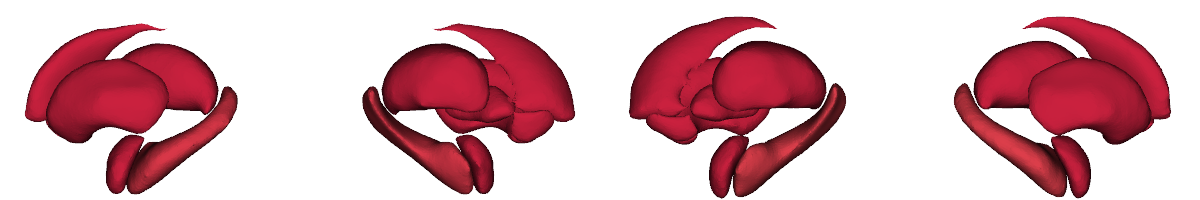

In [43]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_tle_sv'][2], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

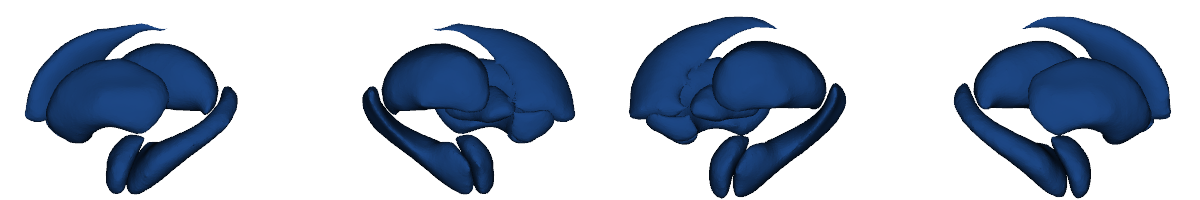

In [ ]:
# plot p-sig areas 
sig_mask = np.where(result_dicts['q_tle_sv'][2] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [45]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

q_sv_hc = pd.Series(result_dicts['q_tle_sv'][2], index=sv_tle.columns, name='pFDR')
q_sv_hc[q_sv_hc < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [46]:
len(q_sv_hc[q_sv_hc < 0.05])

14

In [47]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_sv'][2].min(), result_dicts['cohen_tle_sv'][2].max()

(0.2432063772860161, 0.5621555509003251)

In [49]:
# get the strongest effects (cohen's d values) for p significant regions 
cohen_sv_hc = pd.Series(result_dicts['cohen_tle_sv'][2], index=sv_tle.columns, name="Cohen's_d")

hc_sv = pd.DataFrame({
    "Cohen's d": cohen_sv_hc,
    "q-value": q_sv_hc
})

hc_sig_sv = hc_sv[hc_sv["q-value"] < 0.05].sort_values(by="Cohen's d", ascending=False)
hc_sig_sv

,Cohen's d,q-value
Lpal,0.562156,4.587045e-12
Rthal,0.511631,1.448687e-10
Laccumb,0.511027,1.448687e-10
Rput,0.489810,6.454669e-10
Lput,0.470424,2.293079e-09
Rpal,0.469155,2.293079e-09
Raccumb,0.412505,1.407423e-07
Lthal,0.402312,2.525566e-07
Ramyg,0.400219,2.596745e-07
Lamyg,0.398646,2.606232e-07


Sex diagnosis interaction effects

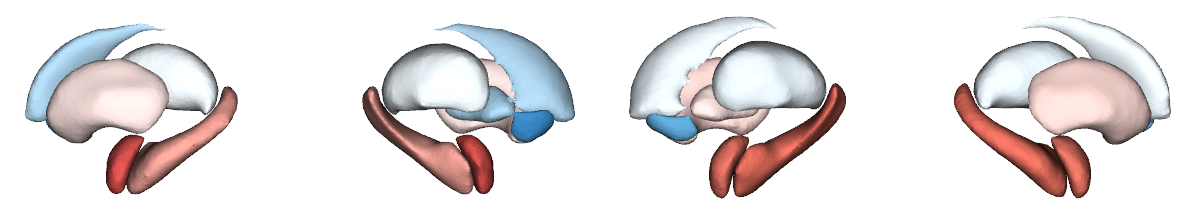

In [52]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['t_tle_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

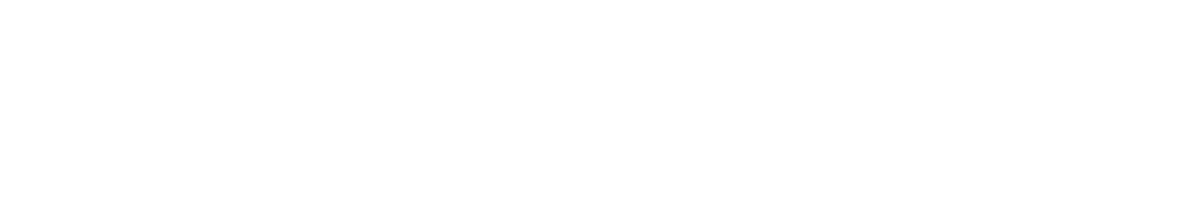

In [53]:
# plot p-sig areas in TLE

sig_mask = np.where(result_dicts['q_tle_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [54]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

## Check which areas are significant in epilepsy
q_sv_tle = pd.Series(result_dicts['q_tle_sv'][3], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index([], dtype='object')

In [55]:
len(q_sv_tle[q_sv_tle < 0.05])

0

In [56]:
# get the t values range for sex in epilepsy
result_dicts['t_tle_sv'][3].min(), result_dicts['t_tle_sv'][3].max()

(-1.9028803642409367, 1.8993359288713074)

### IGE results visualization

#### Cortical thickness 

##### Sex effects in EPI

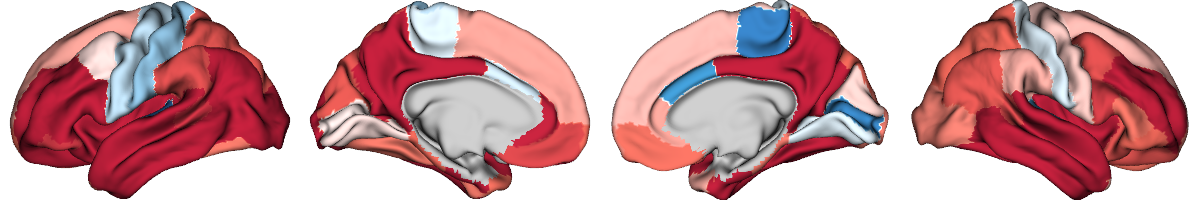

In [57]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_ige_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

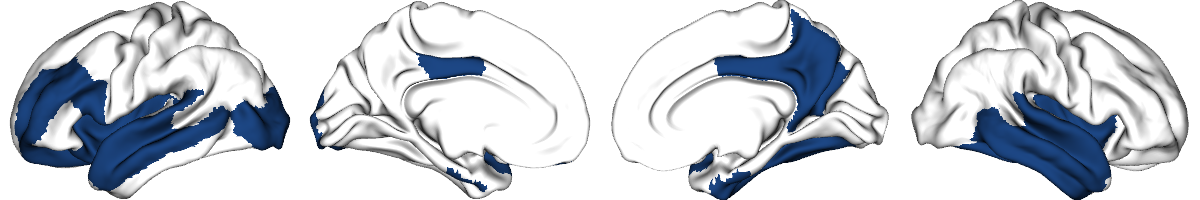

In [60]:
# plot p-sig areas in TLE

p_ctx_surf = parcel_to_surface(result_dicts['q_ige_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [61]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

q_ctx_ige = pd.Series(result_dicts['q_ige_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index(['L_entorhinal', 'L_lateraloccipital', 'L_lateralorbitofrontal',
       'L_middletemporal', 'L_parsopercularis', 'L_posteriorcingulate',
       'L_rostralmiddlefrontal', 'L_superiortemporal', 'L_insula',
       'R_entorhinal', 'R_fusiform', 'R_inferiortemporal',
       'R_isthmuscingulate', 'R_middletemporal', 'R_posteriorcingulate',
       'R_precuneus', 'R_superiortemporal', 'R_insula'],
      dtype='object')

In [62]:
len(q_ctx_ige[q_ctx_ige < 0.05])

18

In [63]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_ige_ctx'][1].min(), result_dicts['cohen_ige_ctx'][1].max()

(-0.24011293474322637, 0.6947502886907939)

In [99]:
# get the strongest effects 
cohen_ctx_ige = pd.Series(result_dicts['cohen_ige_ctx'][1], index=ctx_ige.columns, name="Cohen's_d")

ige_ctx = pd.DataFrame({
    "Cohen's d": cohen_ctx_ige,
    "q-value": q_ctx_ige
})

ige_sig_ctx = ige_ctx[ige_ctx["q-value"] < 0.05].sort_values(by="Cohen's d", ascending=False)
ige_sig_ctx

,Cohen's d,q-value
R_insula,0.694750,0.000131
R_middletemporal,0.507558,0.009393
R_isthmuscingulate,0.497872,0.009393
L_posteriorcingulate,0.497492,0.009393
L_middletemporal,0.483960,0.010506
R_entorhinal,0.470913,0.012013
L_insula,0.454564,0.013659
L_entorhinal,0.453317,0.013659
L_superiortemporal,0.436101,0.017164
R_posteriorcingulate,0.433603,0.017164


Sex effects in healthy control

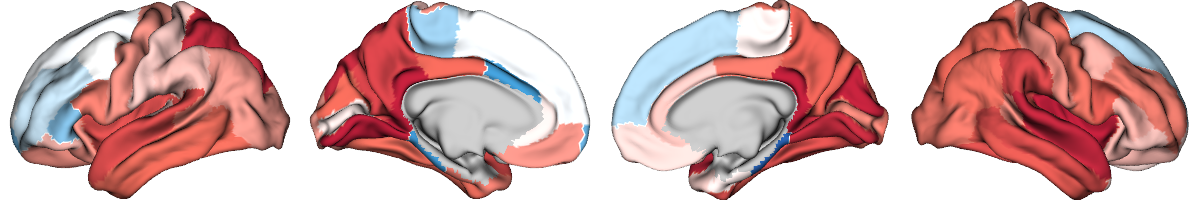

In [64]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_ige_ctx'][2], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

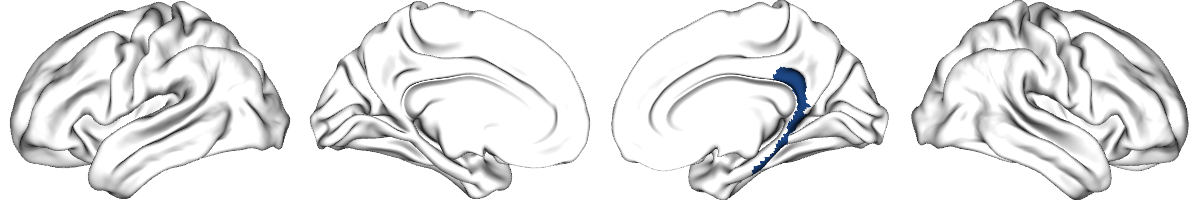

In [67]:
# plot p-sig areas in TLE

p_ctx_surf = parcel_to_surface(result_dicts['q_ige_ctx'][2], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [68]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

q_ctx_hc = pd.Series(result_dicts['q_ige_ctx'][2], index=ctx_ige.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index(['R_isthmuscingulate', 'R_parahippocampal'], dtype='object')

In [69]:
len(q_ctx_hc[q_ctx_hc < 0.05])

2

In [70]:
# get the cohen's d values range 
result_dicts['cohen_ige_ctx'][2].min(), result_dicts['cohen_ige_ctx'][2].max()

(-0.36638582803645725, 0.35941335308832645)

Sex effects in interaction

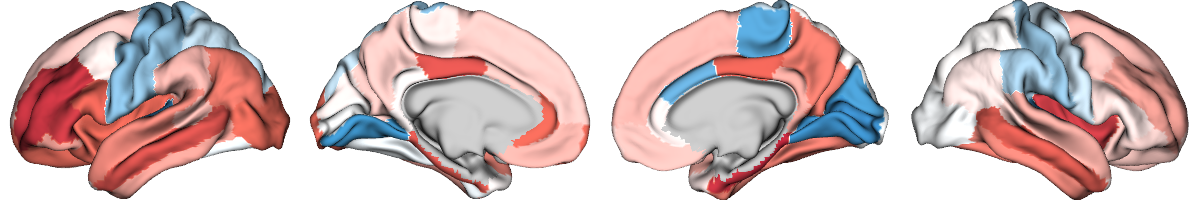

In [76]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['t_ige_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

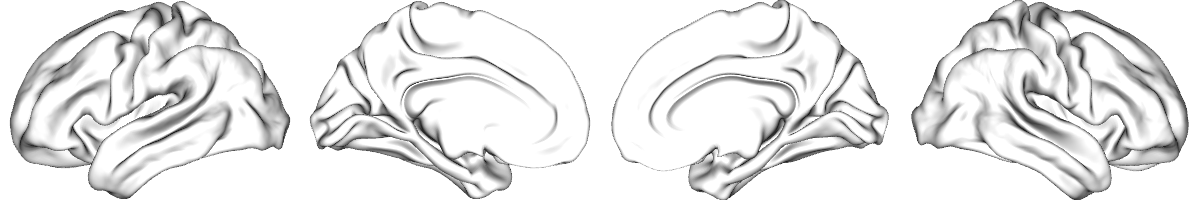

In [77]:
# plot p-sig areas 
p_ctx_surf = parcel_to_surface(result_dicts['q_ige_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [78]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

q_ctx_hc = pd.Series(result_dicts['q_ige_ctx'][3], index=ctx_ige.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index([], dtype='object')

In [79]:
len(q_ctx_hc[q_ctx_hc < 0.05])

0

In [81]:
# get the cohen's d values range
result_dicts['t_ige_ctx'][3].min(), result_dicts['t_ige_ctx'][3].max()

(-1.7974999697896694, 2.7742127818315008)

Subcortical volume

Sex effects in epi

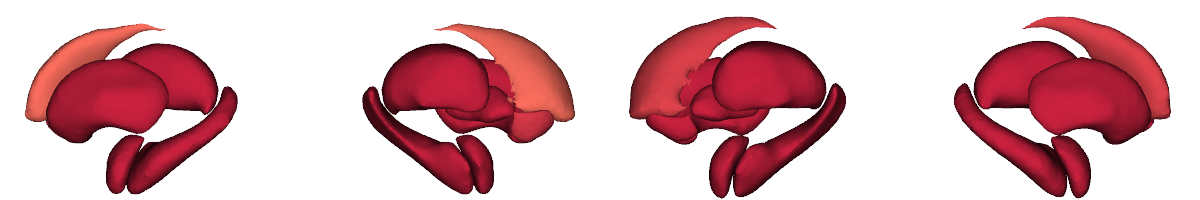

In [82]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_ige_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

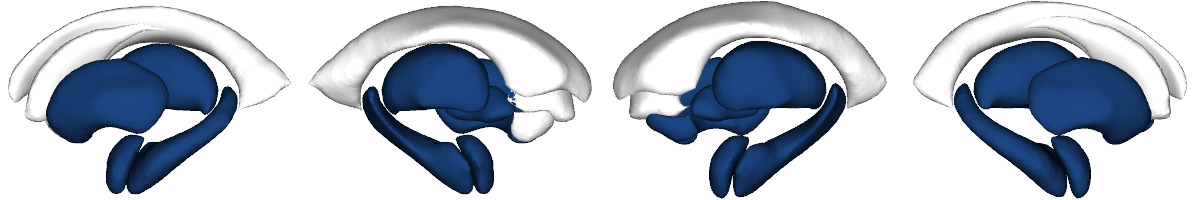

In [83]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_ige_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [84]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

q_sv_ige = pd.Series(result_dicts['q_ige_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05].index

Index(['Lamyg', 'Lhippo', 'Lpal', 'Lput', 'Lthal', 'Raccumb', 'Ramyg',
       'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [85]:
len(q_sv_ige[q_sv_ige < 0.05])

11

In [86]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_ige_sv'][1].min(), result_dicts['cohen_ige_sv'][1].max()

(0.1552127059883081, 0.7998800400389293)

In [100]:
# get the strongest effects for p significant regions 
cohen_sv_ige = pd.Series(result_dicts['cohen_ige_sv'][1], index=sv_ige.columns, name="Cohen's_d")

ige_sv = pd.DataFrame({
    "Cohen's d": cohen_sv_ige,
    "q-value": q_sv_ige
})

ige_sig_sv = ige_sv[ige_sv["q-value"] < 0.05].sort_values(by="Cohen's d", ascending=False)
ige_sig_sv

,Cohen's d,q-value
Ramyg,0.799880,7.625686e-07
Lamyg,0.779268,7.885194e-07
Rput,0.622778,7.171905e-05
Lhippo,0.618163,7.171905e-05
Rthal,0.561767,2.864139e-04
Rhippo,0.537879,4.551485e-04
Raccumb,0.528641,4.978658e-04
Rpal,0.519274,5.350155e-04
Lput,0.516200,5.350155e-04
Lthal,0.505746,6.288993e-04


Sex effects in healthy control

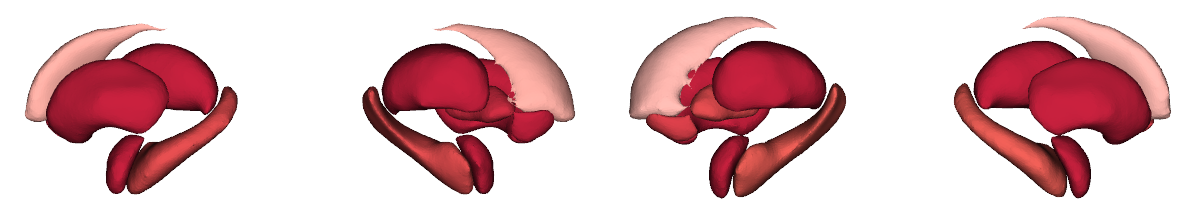

In [87]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_ige_sv'][2], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))


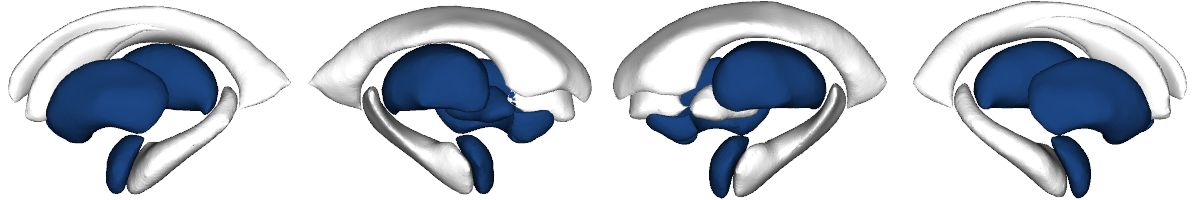

In [88]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_ige_sv'][2] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [89]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

q_sv_hc = pd.Series(result_dicts['q_ige_sv'][2], index=sv_ige.columns, name='pFDR')
q_sv_hc[q_sv_hc < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lpal', 'Lput', 'Lthal', 'Raccumb', 'Ramyg', 'Rput',
       'Rthal'],
      dtype='object')

In [90]:
len(q_sv_hc[q_sv_hc < 0.05])

9

In [91]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_ige_sv'][2].min(), result_dicts['cohen_ige_sv'][2].max()

(0.07812779144524576, 0.4260371968534837)

Sex diagnosis interaction effects

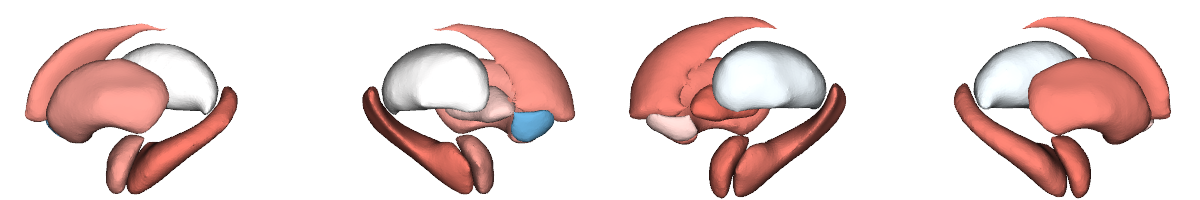

In [93]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['t_ige_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

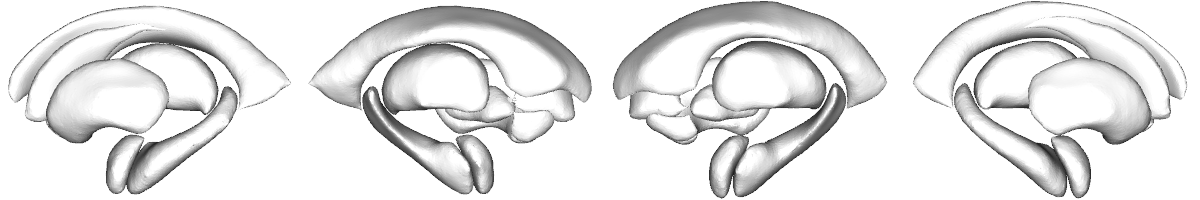

In [94]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_ige_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [95]:
## Check which areas are significant
q_sv_hc = pd.Series(result_dicts['q_ige_sv'][3], index=sv_ige.columns, name='pFDR')
q_sv_hc[q_sv_hc < 0.05].index

Index([], dtype='object')

In [96]:
len(q_sv_hc[q_sv_hc < 0.05])

0

In [98]:
result_dicts['t_ige_sv'][3].min(), result_dicts['t_ige_sv'][3].max()

(-1.213584870147785, 1.4180662544573979)